# Hyper parameters tuning with optuna

In [3]:
import os
import sys
import json
import pickle
import warnings
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import optuna
import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, brier_score_loss, precision_recall_curve

from src.features import add_features, RAW_CATEGORICAL_COLUMNS, RAW_NUMERIC_COLUMNS, INTERACTION_COLUMNS, ENGINEERED_NUMERIC_COLUMNS
from src.split import time_based_split

DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = DATA_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_SPLITS = 5
N_TRIALS = 30
N_JOBS = 4
print("Setup completed successfully!")


Setup completed successfully!


In [4]:
# Tải cache nếu pandas đọc được; nếu cache cũ không tương thích, tạo lại từ train.csv.
feat_path = DATA_DIR / "train_featured.pkl"
df_all = None
if feat_path.exists():
    try:
        df_all = pd.read_pickle(feat_path)
        print("Loaded compatible cache: train_featured.pkl")
    except (NotImplementedError, ValueError, EOFError, pickle.UnpicklingError) as exc:
        print(f"Cache incompatible ({type(exc).__name__}); rebuilding from train.csv")

if df_all is None:
    df_raw = pd.read_csv(DATA_DIR / "train.csv")
    df_all = add_features(df_raw.drop(columns=["is_fraud"]))
    df_all["is_fraud"] = df_raw["is_fraud"].astype(int)
    df_all["id"] = df_raw["id"]
print(f"Dataset shape: {df_all.shape}")
display(df_all.head())


Cache incompatible (NotImplementedError); rebuilding from train.csv
Dataset shape: (699960, 43)


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,txn_intensity_per_day,is_recent_txn,is_high_velocity,balance_amount_ratio,prior_disputes_per_card_age,merchant_category__channel,merchant_category__auth_method,channel__auth_method,device_type__channel,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,0.710690,0,0,20.420689,0.000000,Groceries__POS,Groceries__OTP,POS__OTP,iPhone__POS,0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,2.819107,0,0,125.164537,0.025641,Online Retail__In-App,Online Retail__PIN,In-App__PIN,Android Phone__In-App,0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,3.809524,0,0,142.239130,0.000000,Utilities__Online,Utilities__OTP,Online__OTP,Tablet__Online,0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3.295572,0,0,57.691727,0.000000,Groceries__POS,Groceries__3D Secure,POS__3D Secure,Android Phone__POS,0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3.870968,1,0,5.025670,0.000000,Electronics__Online,Electronics__3D Secure,Online__3D Secure,Windows PC__Online,0


In [5]:
splits = time_based_split(df_all, id_col="id", train_ratio=0.70, valid_ratio=0.15, buffer_size=0)
train_df = splits["train"].sort_values("id").reset_index(drop=True)
valid_df = splits["valid"].sort_values("id").reset_index(drop=True)
test_df = splits["test_holdout"].sort_values("id").reset_index(drop=True)

y_train, y_valid, y_test = train_df["is_fraud"].values, valid_df["is_fraud"].values, test_df["is_fraud"].values
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Samples": [len(train_df), len(valid_df), len(test_df)],
    "Fraud Rate": [y_train.mean(), y_valid.mean(), y_test.mean()]
})
display(split_summary)


,Dataset,Samples,Fraud Rate
0,Train,489971,0.016821
1,Validation,104995,0.016448
2,Test,104994,0.016382


In [6]:
RAW_COLS = RAW_NUMERIC_COLUMNS + RAW_CATEGORICAL_COLUMNS
FEATURE_SETS = {
    "FS_full": RAW_COLS + ENGINEERED_NUMERIC_COLUMNS + INTERACTION_COLUMNS,
    "FS_selected": RAW_COLS + ENGINEERED_NUMERIC_COLUMNS  # 31 features (loại bỏ 4 Interaction gây giảm PR-AUC)
}
# Quyết định chính thức: Sử dụng FS_selected theo kết luận từ NB05
ACTIVE_FEATURE_SET = "FS_selected"
FEATURE_COLS = FEATURE_SETS[ACTIVE_FEATURE_SET]
CAT_COLS = [c for c in FEATURE_COLS if c in RAW_CATEGORICAL_COLUMNS or c in INTERACTION_COLUMNS]
print(f"Selected feature set: {ACTIVE_FEATURE_SET} ({len(FEATURE_COLS)} features, {len(CAT_COLS)} categorical)")


Selected feature set: FS_selected (31 features, 5 categorical)


In [7]:
X_train, X_valid, X_test = train_df[FEATURE_COLS].copy(), valid_df[FEATURE_COLS].copy(), test_df[FEATURE_COLS].copy()
for col in CAT_COLS:
    X_train[col] = X_train[col].astype("category")
    cats = X_train[col].cat.categories
    X_valid[col] = pd.Categorical(X_valid[col], categories=cats)
    X_test[col] = pd.Categorical(X_test[col], categories=cats)
print(f"X_train: {X_train.shape}, X_valid: {X_valid.shape}, X_test: {X_test.shape} | Missing: {X_train.isna().sum().sum()}")


X_train: (489971, 31), X_valid: (104995, 31), X_test: (104994, 31) | Missing: 0


In [8]:
n_neg, n_pos = int((y_train == 0).sum()), int((y_train == 1).sum())
scale_pos_weight = n_neg / n_pos
print(f"Non-fraud: {n_neg:,} | Fraud: {n_pos:,} | Rate: {y_train.mean():.4%} | Imbalance ratio: {scale_pos_weight:.4f}")


Non-fraud: 481,729 | Fraud: 8,242 | Rate: 1.6821% | Imbalance ratio: 58.4481


In [9]:
CV_STRATEGY = "stratified"
print(f"Validation Strategy: {CV_STRATEGY.upper()} 5-FOLD CV")
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE) if CV_STRATEGY == "stratified" else TimeSeriesSplit(n_splits=N_SPLITS)
cv_splits = list(cv.split(X_train, y_train))
fold_summary = []
for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
    y_tr, y_va = y_train[train_idx], y_train[valid_idx]
    fold_summary.append({"Fold": fold, "Train Samples": len(train_idx), "Valid Samples": len(valid_idx),
                         "Train Fraud%": round(y_tr.mean() * 100, 4), "Valid Fraud%": round(y_va.mean() * 100, 4)})
display(pd.DataFrame(fold_summary))


Validation Strategy: STRATIFIED 5-FOLD CV


,Fold,Train Samples,Valid Samples,Train Fraud%,Valid Fraud%
0,1,391976,97995,1.6820,1.6827
1,2,391977,97994,1.6822,1.6817
2,3,391977,97994,1.6822,1.6817
3,4,391977,97994,1.6822,1.6817
4,5,391977,97994,1.6820,1.6828


In [10]:
def objective_lgb(trial):
    max_depth = trial.suggest_int("max_depth", 4, 10)
    params = {
        "objective": "binary", "n_estimators": 2000, "max_depth": max_depth,
        "num_leaves": trial.suggest_int("num_leaves", 15, min(127, 2 ** max_depth)),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 200),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-5, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-5, 20.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, max(1.0, scale_pos_weight), log=True),
        "random_state": RANDOM_STATE, "n_jobs": N_JOBS, "verbosity": -1
    }
    fold_scores, best_iterations = [], []
    for fold, (train_idx, valid_idx) in enumerate(cv_splits):
        X_tr, X_va = X_train.iloc[train_idx].copy(), X_train.iloc[valid_idx].copy()
        y_tr, y_va = y_train[train_idx], y_train[valid_idx]
        for col in CAT_COLS:
            X_tr[col] = X_tr[col].cat.remove_unused_categories()
            X_va[col] = pd.Categorical(X_va[col], categories=X_tr[col].cat.categories)
        model = lgb.LGBMClassifier(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="average_precision",
                  callbacks=[lgb.early_stopping(stopping_rounds=100, first_metric_only=True, verbose=False),
                             lgb.log_evaluation(period=0)])
        score = average_precision_score(y_va, model.predict_proba(X_va)[:, 1])
        fold_scores.append(score)
        best_iterations.append(int(model.best_iteration_))
        trial.report(float(np.mean(fold_scores)), step=fold)
        if trial.should_prune(): raise optuna.TrialPruned()
    trial.set_user_attr("fold_scores", fold_scores)
    trial.set_user_attr("cv_std", float(np.std(fold_scores)))
    trial.set_user_attr("best_iterations", best_iterations)
    return float(np.mean(fold_scores))


In [11]:
study_lgb = optuna.create_study(study_name="lightgbm_pr_auc", direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2))
study_lgb.optimize(objective_lgb, n_trials=N_TRIALS, show_progress_bar=True)


[I 2026-11-21 21:54:43,000] A new study created in memory with name: lightgbm_pr_auc


  0%|          | 0/30 [00:00<?, ?it/s]

d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set

[I 2026-11-21 21:55:38,992] Trial 0 finished with value: 0.3482987796107548 and parameters: {'max_depth': 6, 'num_leaves': 62, 'min_child_samples': 152, 'learning_rate': 0.030049873591901578, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 2.231010801867923e-05, 'reg_lambda': 2.8694712385318164, 'scale_pos_weight': 11.535384585505264}. Best is trial 0 with value: 0.3482987796107548.


d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set

[I 2026-11-21 21:56:19,437] Trial 1 finished with value: 0.3430413783828955 and parameters: {'max_depth': 8, 'num_leaves': 17, 'min_child_samples': 195, 'learning_rate': 0.060534484680010825, 'subsample': 0.6849356442713105, 'colsample_bytree': 0.6727299868828402, 'reg_alpha': 0.00012601639723276795, 'reg_lambda': 0.0008261130806754192, 'scale_pos_weight': 8.455202550290855}. Best is trial 0 with value: 0.3482987796107548.


... (52 outputs left out)

d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set

[I 2026-11-21 22:53:13,894] Trial 28 pruned. 


d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Project\FraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set

[I 2026-11-21 22:54:22,079] Trial 29 pruned. 


Best trial: 21 | Best CV PR-AUC: 0.358561 | CV Std: 0.007565

Best Hyperparameters:
max_depth           : 4
num_leaves          : 15
min_child_samples   : 64
learning_rate       : 0.017247534708389998
subsample           : 0.9699673302580505
colsample_bytree    : 0.778835908327595
reg_alpha           : 0.14932744184603522
reg_lambda          : 0.003976423167105536
scale_pos_weight    : 1.0232387105214913


C:\Users\Admin\AppData\Local\Temp\ipykernel_23140\98799537.py:5: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study_lgb); plt.tight_layout(); plt.show()


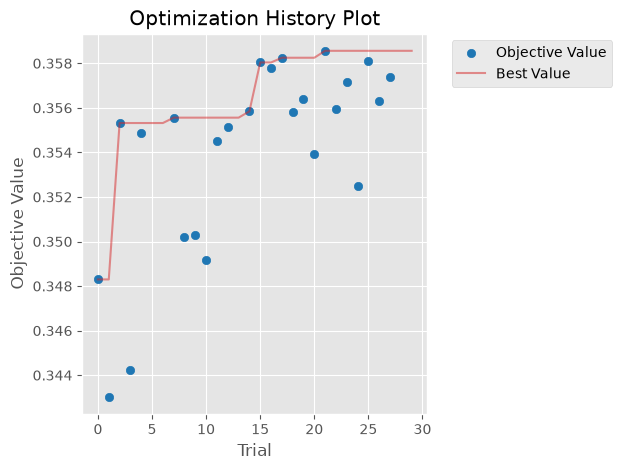

C:\Users\Admin\AppData\Local\Temp\ipykernel_23140\98799537.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study_lgb); plt.tight_layout(); plt.show()


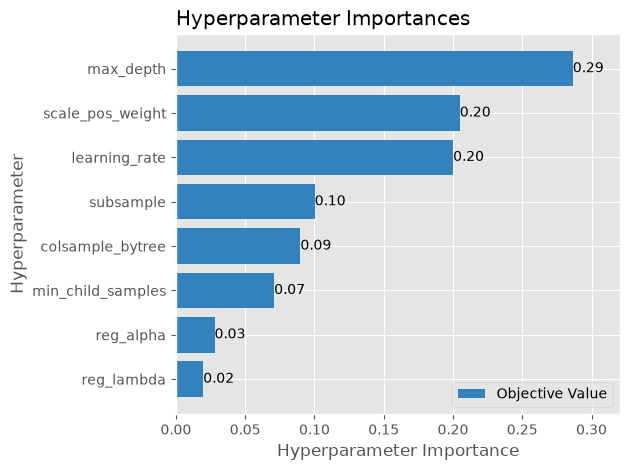

In [12]:
print(f"Best trial: {study_lgb.best_trial.number} | Best CV PR-AUC: {study_lgb.best_value:.6f} | CV Std: {study_lgb.best_trial.user_attrs['cv_std']:.6f}")
print("\nBest Hyperparameters:")
for k, v in study_lgb.best_params.items(): print(f"{k:20s}: {v}")
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
plot_optimization_history(study_lgb); plt.tight_layout(); plt.show()
plot_param_importances(study_lgb); plt.tight_layout(); plt.show()


In [13]:
best_lgb_params = study_lgb.best_params.copy()
best_n_estimators = max(1, int(np.median(study_lgb.best_trial.user_attrs["best_iterations"])))
best_lgb_params.update({"objective": "binary", "n_estimators": best_n_estimators, "subsample_freq": 1,
                        "random_state": RANDOM_STATE, "n_jobs": N_JOBS, "verbosity": -1})
print("Best number of estimators:", best_n_estimators)
display(pd.DataFrame(best_lgb_params.items(), columns=["Parameter", "Value"]))


Best number of estimators: 1955


,Parameter,Value
0,max_depth,4
1,num_leaves,15
2,min_child_samples,64
3,learning_rate,0.017248
4,subsample,0.969967
5,colsample_bytree,0.778836
6,reg_alpha,0.149327
7,reg_lambda,0.003976
8,scale_pos_weight,1.023239
9,objective,binary


In [14]:
lgb_tuned = lgb.LGBMClassifier(**best_lgb_params)
lgb_tuned.fit(X_train, y_train)
lgb_train_probs = lgb_tuned.predict_proba(X_train)[:, 1]
lgb_valid_probs = lgb_tuned.predict_proba(X_valid)[:, 1]
lgb_tuned_ap = average_precision_score(y_valid, lgb_valid_probs)
lgb_tuned_results = {
    "Model": "LightGBM Tuned", "Feature Set": ACTIVE_FEATURE_SET,
    "CV PR-AUC": study_lgb.best_value, "CV Std": study_lgb.best_trial.user_attrs["cv_std"],
    "Train PR-AUC": average_precision_score(y_train, lgb_train_probs), "Valid PR-AUC": lgb_tuned_ap,
    "Valid ROC-AUC": roc_auc_score(y_valid, lgb_valid_probs), "Valid Brier Score": brier_score_loss(y_valid, lgb_valid_probs)
}
display(pd.DataFrame([lgb_tuned_results]))


,Model,Feature Set,CV PR-AUC,CV Std,Train PR-AUC,Valid PR-AUC,Valid ROC-AUC,Valid Brier Score
0,LightGBM Tuned,FS_selected,0.358561,0.007565,0.440771,0.340234,0.911911,0.012973


# XGBoost

In [15]:
def objective_xgb(trial):
    params = {
        "objective": "binary:logistic", "n_estimators": 2000,
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 50.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-5, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-5, 20.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, max(1.0, scale_pos_weight), log=True),
        "tree_method": "hist", "device": "cuda:0", "enable_categorical": True,
        "eval_metric": "aucpr", "early_stopping_rounds": 100, "random_state": RANDOM_STATE, "n_jobs": N_JOBS, "verbosity": 0
    }
    fold_scores, best_iterations = [], []
    for fold, (train_idx, valid_idx) in enumerate(cv_splits):
        X_tr, X_va = X_train.iloc[train_idx].copy(), X_train.iloc[valid_idx].copy()
        y_tr, y_va = y_train[train_idx], y_train[valid_idx]
        for col in CAT_COLS:
            X_tr[col] = X_tr[col].cat.remove_unused_categories()
            X_va[col] = pd.Categorical(X_va[col], categories=X_tr[col].cat.categories)
        model = xgb.XGBClassifier(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        y_prob = model.predict_proba(X_va)[:, 1]
        score = average_precision_score(y_va, y_prob)
        fold_scores.append(float(score))
        best_iterations.append(int(model.best_iteration + 1))
        trial.report(float(np.mean(fold_scores)), step=fold)
        if trial.should_prune(): raise optuna.TrialPruned()
    trial.set_user_attr("fold_scores", fold_scores)
    trial.set_user_attr("cv_std", float(np.std(fold_scores)))
    trial.set_user_attr("best_iterations", best_iterations)
    return float(np.mean(fold_scores))


In [16]:
study_xgb = optuna.create_study(study_name="xgboost_pr_auc", direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2))
study_xgb.optimize(objective_xgb, n_trials=N_TRIALS, show_progress_bar=True)


[I 2026-11-21 22:55:10,179] A new study created in memory with name: xgboost_pr_auc


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-21 22:55:30,447] Trial 0 finished with value: 0.3527126315813486 and parameters: {'max_depth': 5, 'min_child_weight': 41.23206532618726, 'gamma': 3.6599697090570253, 'learning_rate': 0.030049873591901578, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 2.231010801867923e-05, 'reg_lambda': 2.8694712385318164, 'scale_pos_weight': 11.535384585505264}. Best is trial 0 with value: 0.3527126315813486.
[I 2026-11-21 22:55:42,941] Trial 1 finished with value: 0.3319418723664561 and parameters: {'max_depth': 8, 'min_child_weight': 1.0838581269344745, 'gamma': 4.8495492608099715, 'learning_rate': 0.060534484680010825, 'subsample': 0.6849356442713105, 'colsample_bytree': 0.6727299868828402, 'reg_alpha': 0.00012601639723276795, 'reg_lambda': 0.0008261130806754192, 'scale_pos_weight': 8.455202550290855}. Best is trial 0 with value: 0.3527126315813486.
[I 2026-11-21 22:56:33,183] Trial 2 finished with value: 0.3512467799936116 and parameters: {'max_dep

XGBOOST HYPERPARAMETER TUNING RESULTS
Best trial: 25 | Best CV PR-AUC: 0.356933 | CV Std: 0.007982

Best Hyperparameters:
max_depth           : 3
min_child_weight    : 1.94738939111957
gamma               : 1.097646665883592
learning_rate       : 0.019899266747052273
subsample           : 0.769393130040901
colsample_bytree    : 0.8332673547607362
reg_alpha           : 5.815823871147282e-05
reg_lambda          : 0.0002601430465348121
scale_pos_weight    : 1.7216451980491396

Best iterations per fold: [1993, 1850, 1294, 1702, 1998]


C:\Users\Admin\AppData\Local\Temp\ipykernel_23140\3936780108.py:6: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study_xgb); plt.title("XGBoost Optimization History"); plt.tight_layout(); plt.show()


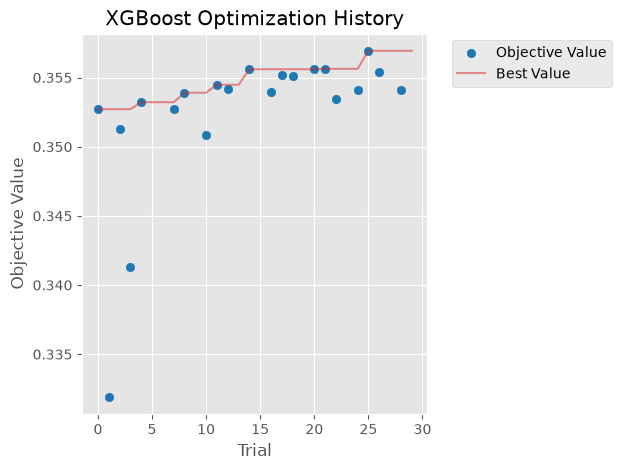

C:\Users\Admin\AppData\Local\Temp\ipykernel_23140\3936780108.py:7: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study_xgb); plt.title("XGBoost Hyperparameter Importance"); plt.tight_layout(); plt.show()


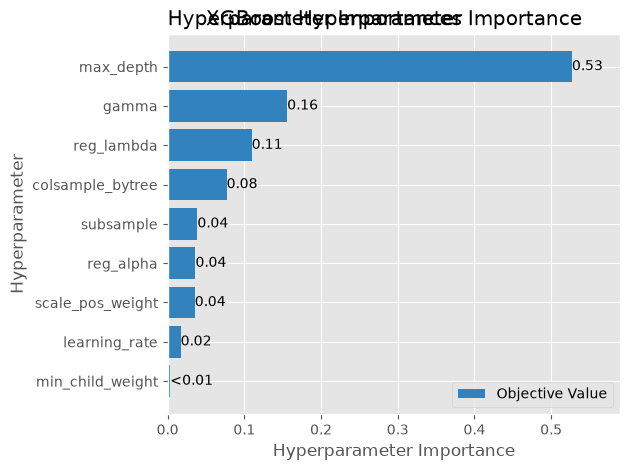

In [17]:
print("=" * 60 + "\nXGBOOST HYPERPARAMETER TUNING RESULTS\n" + "=" * 60)
print(f"Best trial: {study_xgb.best_trial.number} | Best CV PR-AUC: {study_xgb.best_value:.6f} | CV Std: {study_xgb.best_trial.user_attrs['cv_std']:.6f}")
print("\nBest Hyperparameters:")
for k, v in study_xgb.best_params.items(): print(f"{k:20s}: {v}")
print("\nBest iterations per fold:", study_xgb.best_trial.user_attrs["best_iterations"])
plot_optimization_history(study_xgb); plt.title("XGBoost Optimization History"); plt.tight_layout(); plt.show()
plot_param_importances(study_xgb); plt.title("XGBoost Hyperparameter Importance"); plt.tight_layout(); plt.show()


In [18]:
best_xgb_params = study_xgb.best_params.copy()
best_xgb_n_estimators = max(1, int(np.median(study_xgb.best_trial.user_attrs["best_iterations"])))
best_xgb_params.update({"objective": "binary:logistic", "n_estimators": best_xgb_n_estimators,
                        "tree_method": "hist", "enable_categorical": True, "eval_metric": "aucpr",
                        "random_state": RANDOM_STATE, "n_jobs": N_JOBS, "verbosity": 0})
print("Best number of estimators:", best_xgb_n_estimators)
display(pd.DataFrame(best_xgb_params.items(), columns=["Parameter", "Value"]))
xgb_tuned = xgb.XGBClassifier(**best_xgb_params)
xgb_tuned.fit(X_train, y_train)
print("Tuned XGBoost training completed!")


Best number of estimators: 1850


,Parameter,Value
0,max_depth,3
1,min_child_weight,1.947389
2,gamma,1.097647
3,learning_rate,0.019899
4,subsample,0.769393
5,colsample_bytree,0.833267
6,reg_alpha,0.000058
7,reg_lambda,0.00026
8,scale_pos_weight,1.721645
9,objective,binary:logistic


Tuned XGBoost training completed!


In [19]:
xgb_train_probs = xgb_tuned.predict_proba(X_train)[:, 1]
xgb_valid_probs = xgb_tuned.predict_proba(X_valid)[:, 1]
xgb_tuned_ap = average_precision_score(y_valid, xgb_valid_probs)
xgb_tuned_results = {
    "Model": "XGBoost Tuned", "Feature Set": ACTIVE_FEATURE_SET,
    "CV PR-AUC": study_xgb.best_value, "CV Std": study_xgb.best_trial.user_attrs["cv_std"],
    "Train PR-AUC": average_precision_score(y_train, xgb_train_probs), "Valid PR-AUC": xgb_tuned_ap,
    "Valid ROC-AUC": roc_auc_score(y_valid, xgb_valid_probs), "Valid Brier Score": brier_score_loss(y_valid, xgb_valid_probs)
}
display(pd.DataFrame([xgb_tuned_results]))


,Model,Feature Set,CV PR-AUC,CV Std,Train PR-AUC,Valid PR-AUC,Valid ROC-AUC,Valid Brier Score
0,XGBoost Tuned,FS_selected,0.356933,0.007982,0.395715,0.33991,0.912459,0.013394


In [20]:
tuned_models_summary = pd.DataFrame([lgb_tuned_results, xgb_tuned_results]).sort_values(by="Valid PR-AUC", ascending=False).reset_index(drop=True)
display(tuned_models_summary.round(6))


,Model,Feature Set,CV PR-AUC,CV Std,Train PR-AUC,Valid PR-AUC,Valid ROC-AUC,Valid Brier Score
0,LightGBM Tuned,FS_selected,0.358561,0.007565,0.440771,0.340234,0.911911,0.012973
1,XGBoost Tuned,FS_selected,0.356933,0.007982,0.395715,0.339910,0.912459,0.013394


In [21]:
prediction_df = pd.DataFrame({"LightGBM": lgb_valid_probs, "XGBoost": xgb_valid_probs})
print(f"Pearson correlation : {prediction_df.corr(method='pearson').iloc[0, 1]:.6f}")
print(f"Spearman correlation: {prediction_df.corr(method='spearman').iloc[0, 1]:.6f}")


Pearson correlation : 0.980892
Spearman correlation: 0.993715


In [22]:
ensemble_avg_probs = 0.5 * lgb_valid_probs + 0.5 * xgb_valid_probs
ensemble_avg_ap = average_precision_score(y_valid, ensemble_avg_probs)
print(f"LightGBM PR-AUC : {lgb_tuned_ap:.6f} | XGBoost PR-AUC : {xgb_tuned_ap:.6f} | Ensemble PR-AUC : {ensemble_avg_ap:.6f}")


LightGBM PR-AUC : 0.340234 | XGBoost PR-AUC : 0.339910 | Ensemble PR-AUC : 0.341162


In [23]:
blend_results = [{"LightGBM Weight": float(a), "XGBoost Weight": float(1 - a),
                  "Valid PR-AUC": float(average_precision_score(y_valid, a * lgb_valid_probs + (1 - a) * xgb_valid_probs))}
                 for a in np.linspace(0, 1, 101)]
blend_df = pd.DataFrame(blend_results)
best_blend = blend_df.loc[blend_df["Valid PR-AUC"].idxmax()]
best_alpha, best_blend_ap = float(best_blend["LightGBM Weight"]), float(best_blend["Valid PR-AUC"])
print(f"Optimal Blending -> LightGBM: {best_alpha:.2f}, XGBoost: {1 - best_alpha:.2f} | Best PR-AUC: {best_blend_ap:.6f}")


Optimal Blending -> LightGBM: 0.58, XGBoost: 0.42 | Best PR-AUC: 0.341321


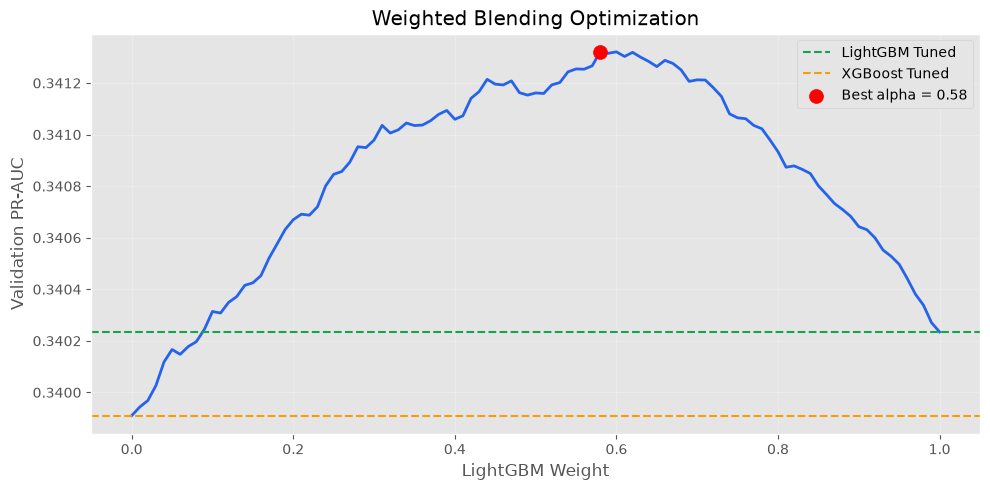

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(blend_df["LightGBM Weight"], blend_df["Valid PR-AUC"], color="#2563eb", linewidth=2)
ax.axhline(lgb_tuned_ap, color="#16a34a", linestyle="--", label="LightGBM Tuned")
ax.axhline(xgb_tuned_ap, color="#f59e0b", linestyle="--", label="XGBoost Tuned")
ax.scatter(best_alpha, best_blend_ap, color="red", s=100, zorder=5, label=f"Best alpha = {best_alpha:.2f}")
ax.set_xlabel("LightGBM Weight"); ax.set_ylabel("Validation PR-AUC"); ax.set_title("Weighted Blending Optimization")
ax.legend(); ax.grid(alpha=0.25); plt.tight_layout(); plt.show()


In [25]:
best_blend_probs = best_alpha * lgb_valid_probs + (1 - best_alpha) * xgb_valid_probs
candidate_predictions = {"LightGBM Tuned": lgb_valid_probs, "XGBoost Tuned": xgb_valid_probs,
                         "Simple Averaging": ensemble_avg_probs, "Weighted Blending": best_blend_probs}
final_results = [{"Model": name, "Valid PR-AUC": average_precision_score(y_valid, p),
                  "Valid ROC-AUC": roc_auc_score(y_valid, p), "Valid Brier Score": brier_score_loss(y_valid, p)}
                 for name, p in candidate_predictions.items()]
final_comparison = pd.DataFrame(final_results).sort_values(by="Valid PR-AUC", ascending=False).reset_index(drop=True)
display(final_comparison.round(6))
best_single_ap = max(lgb_tuned_ap, xgb_tuned_ap)
ensemble_gain = best_blend_ap - best_single_ap
print(f"Best single: {best_single_ap:.6f} | Best ensemble: {best_blend_ap:.6f} | Gain: {ensemble_gain:+.6f} ({(ensemble_gain / best_single_ap) * 100:+.2f}%)")


,Model,Valid PR-AUC,Valid ROC-AUC,Valid Brier Score
0,Weighted Blending,0.341321,0.912565,0.013043
1,Simple Averaging,0.341162,0.912591,0.013074
2,LightGBM Tuned,0.340234,0.911911,0.012973
3,XGBoost Tuned,0.339910,0.912459,0.013394


Best single: 0.340234 | Best ensemble: 0.341321 | Gain: +0.001087 (+0.32%)


In [26]:
MIN_ENSEMBLE_GAIN = 0.001
best_single_model = "LightGBM" if lgb_tuned_ap >= xgb_tuned_ap else "XGBoost"
final_model_name = "Weighted Blending" if ensemble_gain >= MIN_ENSEMBLE_GAIN else best_single_model
final_valid_ap = best_blend_ap if ensemble_gain >= MIN_ENSEMBLE_GAIN else best_single_ap
print(f"FINAL MODEL SELECTION: {final_model_name} (Validation AP: {final_valid_ap:.6f})")


FINAL MODEL SELECTION: Weighted Blending (Validation AP: 0.341321)


In [27]:
final_config = {
    "selected_model": final_model_name, "optimization_metric": "average_precision",
    "feature_set": ACTIVE_FEATURE_SET, "feature_columns": list(FEATURE_COLS),
    "categorical_columns": list(CAT_COLS), "cv_strategy": CV_STRATEGY,
    "n_splits": N_SPLITS, "random_state": RANDOM_STATE,
    "lightgbm_params": best_lgb_params, "xgboost_params": best_xgb_params,
    "ensemble_weights": {"lightgbm": best_alpha, "xgboost": 1 - best_alpha},
    "validation_results": {"lightgbm_ap": float(lgb_tuned_ap), "xgboost_ap": float(xgb_tuned_ap),
                           "ensemble_ap": float(best_blend_ap), "final_ap": float(final_valid_ap)}
}
with open(ARTIFACT_DIR / "final_model_config.json", "w", encoding="utf-8") as f:
    json.dump(final_config, f, indent=4)
blend_df.to_csv(ARTIFACT_DIR / "ensemble_weight_search.csv", index=False)
final_comparison.to_csv(ARTIFACT_DIR / "final_model_comparison.csv", index=False)
print("Final model configuration saved successfully!")


Final model configuration saved successfully!
